# Analyse Big Data des accidents de la route en Australie-Méridionale avec PySpark

**Source :** ce notebook reprend le code de l'article *« Big data Analysis of Road Crash Data using PySpark
with PySpark Tutorial »* de Rakesh Nain (Medium, janvier 2021), et son dépôt GitHub
`RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial`.

**Ce que nous avons ajouté au code original :**
- des **explications** des notions Spark utilisées (RDD, partitions, transformations et actions, jointures,
  UDF, Spark SQL…), avant chaque bloc de code ;
- des **commentaires** dans le code et une **lecture commentée** de chaque résultat et de chaque figure ;
- des **vérifications** : en exécutant le code, nous avons trouvé plusieurs erreurs dans l'article.
  Chaque erreur est signalée par **Correction**, expliquée, puis corrigée. Le code original est conservé
  à côté de la version corrigée pour pouvoir comparer.

| # | Problème trouvé dans le code original | Conséquence |
|---|---|---|
| 1 | La partition « par Lic State » utilise en fait la colonne `Veh Reg State` (indice 3) | mauvaise interprétation du résultat |
| 2 | Les lignes de `crash` sont découpées avec `split(',')`, alors que 21 379 lignes contiennent une virgule *à l'intérieur* d'un champ | colonnes décalées dans les requêtes RDD |
| 3 | Requête RDD « Adelaide » : mauvais indices de colonnes (âge, état du permis, remorquage… au lieu de sexe, âge, type de permis) | résultat faux |
| 4 | Requête « victimes par suburb pour les conducteurs sans permis » : les trois versions RDD / DataFrame / SQL calculent trois choses différentes, et aucune ne filtre les conducteurs sans permis | résultats incohérents entre eux |
| 5 | Après la jointure crash ⋈ units, un accident est compté une fois **par véhicule** | double comptage des victimes |

**Organisation du dossier.** Le notebook doit se trouver à côté des dossiers du dépôt de l'auteur :
`units_data/`, `crash_data/` et `data for given tutorials/` (pour l'exemple `bank.csv`).

## 1. Les données

Les données sont publiées par le *Department of Planning, Transport and Infrastructure* (DPTI) d'Australie-Méridionale
sur https://data.sa.gov.au. Elles couvrent les années **2012 à 2019**, avec un fichier CSV par année et par table.
Nous utilisons deux tables :

| Table | Une ligne = | Lignes | Colonnes utiles |
|---|---|---|---|
| **Crash** (`crash_data/`) | un **accident** | 127 672 | `REPORT_ID`, `Suburb` (quartier/commune), `Total Cas` (nombre total de victimes), `Total Fats` (nombre de tués), `Crash Type`, `CSEF Severity` (gravité), `DUI Involved` (alcool), `Drugs Involved` (drogues), `Year`, `Month`, `Day`, `Time` |
| **Units** (`units_data/`) | une **unité** impliquée dans un accident : véhicule, piéton, obstacle… | 272 591 | `REPORT_ID`, `No Of Cas`, `Veh Reg State` (état d'immatriculation), `Unit Type`, `Veh Year` (année du véhicule), `Sex`, `Age`, `Lic State` (état du permis), `Licence Type` |

**Lien entre les deux tables.** La colonne `REPORT_ID` identifie un accident. Un accident (une ligne de *Crash*)
implique **plusieurs** unités (plusieurs lignes de *Units*) : c'est une relation **un-à-plusieurs** (1 → n).
Il faudra s'en souvenir lors des jointures (voir section 4.4).

**Valeurs manquantes.** Les données utilisent plusieurs conventions : champ vide, `XXX` / `XXXX`, `Unknown`
ou `UNKNOWN`. Il faut les filtrer avant de calculer une moyenne ou un tri.

**Date.** Le jour exact de l'accident n'est pas publié (donnée sensible) : `Day` contient le **jour de la semaine**.
Les dates sont donc affichées au format `Année-Mois-JourDeLaSemaine`, par exemple `2017-January-Sunday`.

## 2. Rappels sur Spark et PySpark

**Spark** est un moteur de calcul distribué : il découpe les données en morceaux (**partitions**) et traite
ces morceaux en parallèle. **PySpark** est son interface Python ; le moteur lui-même s'exécute dans une machine
virtuelle Java (JVM).

**Calcul parallèle ou distribué ?**
- *Parallèle* : plusieurs cœurs d'**une seule** machine travaillent en même temps.
- *Distribué* : plusieurs **machines** reliées par le réseau travaillent en même temps.

Spark gère les deux avec le même code : seule l'adresse du *master* change. Ici, nous travaillons en
**mode local** (`local[*]`), donc en calcul parallèle sur les cœurs de notre machine.

**Architecture d'une application Spark.**
- Le **driver** est le programme principal (ici, le noyau du notebook) : il construit le plan de calcul et
  récupère les résultats.
- Les **executors** exécutent les **tâches**, à raison d'une tâche par partition. En mode local, ce sont des
  threads de la même JVM.

**Transformations et actions.**
- Une *transformation* (`map`, `filter`, `join`, `groupBy`…) décrit un nouveau jeu de données **sans rien calculer** :
  c'est l'**évaluation paresseuse** (*lazy evaluation*).
- Une *action* (`count`, `collect`, `take`, `show`…) déclenche réellement le calcul de toute la chaîne de transformations.

Ce mécanisme permet à Spark d'optimiser l'ensemble du calcul avant de l'exécuter, mais il implique qu'une
erreur dans une transformation n'apparaît qu'au moment de l'action.

### 2.1 Importation des bibliothèques (code original)
- `SparkConf`, `SparkContext`, `SparkSession` : configuration et points d'entrée de Spark ;
- `pyspark.sql.functions` (`F`, `col`, `udf`) : fonctions de manipulation des colonnes de DataFrame ;
- `pyspark.sql.types` : types de colonnes (`IntegerType`, `FloatType`, `StringType`…), utilisés pour
  convertir les colonnes et déclarer le type de retour des UDF ;
- `RDD` : la classe des RDD, utilisée pour tester le type d'un objet ;
- `pandas` et `matplotlib` : pour les graphiques, une fois les résultats ramenés sur le driver.

In [1]:
from pyspark import SparkConf
from pyspark import SparkContext
from pyspark.sql import SparkSession
from pyspark.sql.functions import udf
from pyspark.sql.types import IntegerType
from pyspark.sql.types import LongType
from pyspark.sql.types import FloatType
from pyspark.rdd import RDD
from pyspark.sql.types import StringType
from pyspark.sql.functions import col
import pyspark.sql.functions as F
import csv
from datetime import datetime
from functools import reduce
import pandas as pd
import matplotlib.pyplot as plt

### 2.2 Configuration et création de la session Spark

**Ajout pour Windows.** Les quatre lignes `os.environ` ne sont pas dans l'article. Elles reprennent les réglages
qui ont été nécessaires dans le TP précédent sous Windows :
- `JAVA_HOME` : Spark 3.5 exige Java 8, 11 ou 17 ;
- `PYSPARK_PYTHON` : les processus Python lancés par Spark doivent utiliser le même Python que le notebook ;
- `SPARK_LOCAL_IP` : évite un blocage au démarrage lié aux cartes réseau virtuelles de Docker.

Ces réglages n'ont aucun effet sous Linux ou macOS.

**Code original.**
- `SparkConf` regroupe les paramètres de l'application : `setMaster("local[*]")` demande le mode local avec
  autant de threads que de cœurs logiques (`local[4]` en utiliserait 4), et `setAppName` donne le nom affiché
  dans l'interface web de Spark (http://localhost:4040).
- `SparkSession` est le point d'entrée unique depuis Spark 2.0 : elle donne accès aux DataFrames et à Spark SQL.
  `getOrCreate()` réutilise la session si elle existe déjà.
- `spark.sparkContext` (`sc`) est l'ancien point d'entrée, toujours nécessaire pour créer des **RDD**.

In [2]:
import os, sys
# --- Ajout : réglages pour Windows (voir le TP précédent) ---
if os.name == "nt":
    JAVA8 = r"C:\Program Files\Java\jre1.8.0_461"      # adapter au dossier Java de la machine
    if os.path.exists(JAVA8):
        os.environ["JAVA_HOME"] = JAVA8
    os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# --- Code original ---
# local[*] : mode local (calcul parallèle) avec autant de threads que de cœurs logiques
master = "local[4]"     # 4 threads au lieu de 8 : moins de processus Python en mémoire en même temps
# nom de l'application, affiché dans l'interface web de Spark
app_name = "Big data Analysis of Road Crash Data"
# paramètres de configuration de Spark
# paramètres de configuration de Spark
spark_conf = SparkConf().setMaster(master).setAppName(app_name)\
                        .set("spark.driver.memory", "4g")\
                        .set("spark.python.worker.memory", "512m")
# création de la SparkSession (et donc du SparkContext)
spark = SparkSession.builder.config(conf=spark_conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel('ERROR')            # n'afficher que les erreurs dans les journaux

print("Spark", spark.version, "| cœurs utilisés :", sc.defaultParallelism)

Spark 3.5.9 | cœurs utilisés : 4


### 2.3 Localisation des fichiers de données (ajout pour Windows)

**Pourquoi cet ajout ?** L'article lit les fichiers avec un joker : `sc.textFile('./units_data/*.csv')`.
Sous Windows, pour développer un joker, la bibliothèque Hadoop intégrée à Spark appelle une fonction native
Windows (`hadoop.dll`, fournie avec l'outil `winutils`) qui n'est pas installée par `pip install pyspark`.
On obtient alors l'erreur `UnsatisfiedLinkError: ...NativeIO$Windows.access0`.

**Contournement :** c'est **Python** (module `glob`) qui liste les fichiers, et l'on donne à Spark leurs chemins exacts,
sous forme d'URI `file:///C:/...`. Lire un fichier précis ne nécessite pas la fonction native. Le résultat est
strictement le même qu'avec le joker. Sous Linux ou macOS, le joker fonctionne directement.

Pour la même raison de robustesse, la cellule cherche aussi le dossier `units_data` s'il ne se trouve pas
à côté du notebook (par exemple dans un sous-dossier créé lors de la décompression du ZIP).

- `UNITS_FILES`, `CRASH_FILES` : listes des chemins, pour `spark.read` (DataFrames) ;
- `UNITS_TXT`, `CRASH_TXT` : les mêmes chemins séparés par des virgules, format attendu par `sc.textFile` (RDD).

In [3]:
import glob

# si units_data n'est pas à côté du notebook, on le cherche dans les sous-dossiers
if not os.path.isdir("units_data"):
    trouves = glob.glob("**/units_data", recursive=True)
    if trouves:
        os.chdir(os.path.dirname(os.path.abspath(trouves[0])))
print("Dossier de travail :", os.getcwd())

def fichier_uri(chemin):
    # chemin local -> URI comprise par Spark sous Windows comme sous Linux (file:///C:/...)
    return "file:///" + os.path.abspath(chemin).replace("\\", "/").lstrip("/")

UNITS_FILES = [fichier_uri(f) for f in sorted(glob.glob("units_data/*.csv"))]
CRASH_FILES = [fichier_uri(f) for f in sorted(glob.glob("crash_data/*.csv"))]
UNITS_TXT = ",".join(UNITS_FILES)       # format attendu par sc.textFile : chemins séparés par des virgules
CRASH_TXT = ",".join(CRASH_FILES)
assert len(UNITS_FILES) == 8 and len(CRASH_FILES) == 8, "il faut 8 fichiers units et 8 fichiers crash"
print(len(UNITS_FILES), "fichiers units |", len(CRASH_FILES), "fichiers crash")
print("Exemple :", UNITS_FILES[0])

Dossier de travail : C:\Users\Brahimi\Desktop\2026_2027\Big_Data\Big_Data
8 fichiers units | 8 fichiers crash
Exemple : file:///C:/Users/Brahimi/Desktop/2026_2027/Big_Data/Big_Data/units_data/2012_DATA_SA_Units.csv


## 3. Analyse avec les RDD

Un **RDD** (*Resilient Distributed Dataset*) est l'abstraction de base de Spark : une collection d'objets
Python quelconques, **immuable** (on ne la modifie pas, on en crée une nouvelle par transformation) et
**répartie en partitions**.
« *Resilient* » signifie que Spark mémorise la suite de transformations qui a produit chaque RDD (son **lignage**) :
si une partition est perdue, par exemple à cause de la panne d'une machine, Spark la recalcule à partir de ce lignage.

Avec les RDD, Spark ne connaît pas la structure des données : c'est au programmeur de découper les lignes
et de savoir que, par exemple, la colonne n°8 est l'âge.

### 3.1 Créer un RDD avec `parallelize()`
`parallelize()` distribue une collection Python (liste, tuple, ensemble) présente sur le driver.
Par défaut, le nombre de partitions est égal au nombre de cœurs ; on peut l'imposer avec le second argument.

In [4]:
## À PARTIR D'UNE LISTE
data_list = [i for i in range(10)]
rdd = sc.parallelize(data_list)
# nombre de partitions par défaut (= nombre de cœurs)
print('Default partitions: ', rdd.getNumPartitions())
# second argument : nombre de partitions choisi manuellement
rdd = sc.parallelize(data_list, 5)
print('Manual partitions: ', rdd.getNumPartitions())
# glom() regroupe les éléments de chaque partition dans une liste : on voit la répartition
print('Contenu des partitions :', rdd.glom().collect())
# collect() est une ACTION : elle ramène tous les éléments sur le driver
rdd.collect()

Default partitions:  4
Manual partitions:  5
Contenu des partitions : [[0, 1], [2, 3], [4, 5], [6, 7], [8, 9]]


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

**Lecture.** Les 10 éléments sont répartis en 5 partitions de 2 éléments consécutifs. Chaque partition sera
traitée par une tâche ; avec plusieurs cœurs, ces tâches s'exécutent en même temps.
`glom()` n'est pas dans l'article : nous l'ajoutons pour **voir** les partitions.

### 3.2 Charger les fichiers CSV avec `textFile()`
`textFile()` lit un ou plusieurs fichiers texte et renvoie un **RDD de chaînes de caractères**, avec un élément par ligne.
L'article utilise le joker `'./units_data/*.csv'` ; nous passons à la place la liste explicite des 8 fichiers
(`UNITS_TXT`, voir section 2.3), ce qui revient au même : les 8 fichiers annuels sont chargés dans un seul RDD.
À ce stade, rien n'est lu (évaluation paresseuse).

In [5]:
# tous les fichiers "Units" 2012-2019 dans un seul RDD
units_rdd = sc.textFile(UNITS_TXT)
# tous les fichiers "Crash" 2012-2019 dans un seul RDD
crash_rdd = sc.textFile(CRASH_TXT)

### 3.3 Supprimer les lignes d'en-tête
Chacun des 8 fichiers commence par une ligne d'en-tête (les noms des colonnes) : le RDD contient donc
**8 en-têtes identiques** mélangés aux données.
- `first()` (action) récupère la première ligne, qui est un en-tête ;
- `filter(lambda row: row != header)` (transformation) supprime toutes les lignes égales à cet en-tête.
  Comme les 8 en-têtes sont identiques, ils sont tous supprimés.
- `count()` compte les lignes et `take(n)` renvoie les n premières : ce sont des actions.

In [6]:
# suppression de l'en-tête de units_rdd
units_header = units_rdd.first()
units_rdd = units_rdd.filter(lambda row: row != units_header)   # retire les 8 en-têtes
print("Total count of units_rdd: ", units_rdd.count())
print(units_rdd.take(3))     # l'article affiche 10 lignes ; 3 suffisent pour voir le format

Total count of units_rdd:  272591
['"2012-1-21/08/2019","01",0,,"Pedal Cycle",,"South West","Male","035",,,,,"Straight Ahead","001","5074",,', '"2012-1-21/08/2019","02",0,"SA","Motor Cars - Sedan","2009","North West","Female","050","SA","C ","Full","Unknown","Leaving Private Driveway","001","5089",,', '"2012-2-21/08/2019","01",0,"SA","Motor Cars - Sedan","1999","West","Male","027","SA",,"Provisional 1 ","Not Towing","Straight Ahead","002","5008",,']


In [7]:
# suppression de l'en-tête de crash_rdd
crash_header = crash_rdd.first()
crash_rdd = crash_rdd.filter(lambda row: row != crash_header)
print("Total count of crash_rdd: ", crash_rdd.count())
print(crash_rdd.take(3))

Total count of crash_rdd:  127672
['"2012-1-21/08/2019","2 Metropolitan","STEPNEY","5069","CC OF NORWOOD,PAYNEHAM & ST PETERS",2,0,0,0,0,2012,"January","Sunday","04:30 pm","060","Not Divided","Straight road","Level","Driveway or Entrance","Sealed","Dry","Not Raining","Daylight","Right Angle","02","Driver Rider","1: PDO","No Control","","",1330659.71,1671795.87,"13306601671796"', '"2012-2-21/08/2019","2 Metropolitan","PARKSIDE","5063","CITY OF UNLEY",2,0,0,0,0,2012,"January","Sunday","09:10 am","040","Not Divided","Straight road","Level","Not Applicable","Sealed","Dry","Not Raining","Daylight","Hit Parked Vehicle","01","Driver Rider","1: PDO","No Control","","",1329400.16,1668462.66,"13294001668463"', '"2012-3-21/08/2019","2 Metropolitan","SELLICKS BEACH","5174","CITY OF ONKAPARINGA",3,0,0,0,0,2012,"January","Wednesday","11:30 am","100","Not Divided","Straight road","Slope","Not Applicable","Sealed","Dry","Not Raining","Daylight","Other","01","Driver Rider","1: PDO","No Control","","",1

**Lecture.** 272 591 unités et 127 672 accidents, soit environ **2,1 unités par accident** en moyenne,
ce qui est cohérent avec la relation 1 → n. Chaque élément est une ligne brute, avec ses guillemets : il faudra la découper.

### 3.4 Partitionnement

**Correction.** L'article affirme que Spark répartit les données « aléatoirement et à parts égales »
(*random equal partitioning*). Ce n'est pas le cas pour `textFile` : Spark découpe chaque **fichier** en
morceaux (*splits*) d'au plus 32 Mo en mode local. Nos fichiers annuels étant plus petits que cela, on obtient
**une partition par fichier, donc par année**.

In [8]:
print("Units Data:")
print(f"Total partitions: {units_rdd.getNumPartitions()}")
print("Crash Data:")
print(f"Total partitions: {crash_rdd.getNumPartitions()}")

Units Data:
Total partitions: 8
Crash Data:
Total partitions: 8


### 3.5 Partitionnement personnalisé

On peut choisir soi-même dans quelle partition va chaque élément. Pour cela, le RDD doit être un
**RDD clé-valeur** (*pair RDD*), dont chaque élément est un couple `(clé, valeur)` : la partition est choisie
en fonction de la clé.

L'auteur veut séparer les véhicules **immatriculés en Australie-Méridionale (SA)** des autres.

**Étape 1 : construire les paires.** La fonction `parseRecord` découpe une ligne sur les virgules, retire les
guillemets, et renvoie `(colonne n°3, toutes les autres colonnes)`.

**Correction.** L'article parle de la colonne `Lic State` (état qui a délivré le **permis**), mais la colonne
d'indice 3 est `Veh Reg State` (état d'**immatriculation du véhicule**). `Lic State` est la colonne d'indice 9.
On garde le code de l'auteur, mais on interprète le résultat comme l'état d'immatriculation.

In [9]:
# en-tête de units, avec l'indice de chaque colonne
print(list(enumerate(units_header.replace('"', '').split(','))))

[(0, 'REPORT_ID'), (1, 'Unit No'), (2, 'No Of Cas'), (3, 'Veh Reg State'), (4, 'Unit Type'), (5, 'Veh Year'), (6, 'Direction Of Travel'), (7, 'Sex'), (8, 'Age'), (9, 'Lic State'), (10, 'Licence Class'), (11, 'Licence Type'), (12, 'Towing'), (13, 'Unit Movement'), (14, 'Number Occupants'), (15, 'Postcode'), (16, 'Rollover'), (17, 'Fire')]


In [10]:
# fonction appliquée à chaque élément du RDD : ligne -> (clé = colonne 3, valeur = autres colonnes)
def parseRecord(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))     # retire les guillemets
    return (array_line[3], [x for i, x in enumerate(array_line) if i != 3])

units_state_rdd = units_rdd.map(parseRecord)
units_state_rdd.take(1)

[('',
  ['2012-1-21/08/2019',
   '01',
   '0',
   'Pedal Cycle',
   '',
   'South West',
   'Male',
   '035',
   '',
   '',
   '',
   '',
   'Straight Ahead',
   '001',
   '5074',
   '',
   ''])]

**Étape 2 : partitionner.** `partitionBy(n, f)` crée `n` partitions et envoie chaque paire dans la partition
numéro `f(clé)`. La fonction `hash_SA` renvoie 0 pour `SA` et 1 pour tout le reste (autres états, valeurs manquantes).
C'est une opération de **shuffle** : les données sont redistribuées entre partitions.

In [11]:
# partition 0 : véhicules immatriculés en SA ; partition 1 : tout le reste
def hash_SA(key):
    if key == 'SA':
        return 0
    else:
        return 1

SA_partitioned_rdd = units_state_rdd.partitionBy(2, hash_SA)

**Étape 3 : compter les éléments de chaque partition.** `glom()` transforme chaque partition en une liste,
et `collect()` ramène ces listes sur le driver. La fonction accepte un RDD ou un DataFrame (dont on prend le RDD
sous-jacent avec `.rdd`).

*Remarque :* `glom().collect()` ramène **toutes les données** sur le driver juste pour les compter. Sur de vraies
données massives, il vaudrait mieux compter dans chaque partition et ne ramener que les nombres :
`rdd.mapPartitions(lambda it: [sum(1 for _ in it)]).collect()`.

In [12]:
# affiche le nombre d'éléments de chaque partition d'un RDD ou d'un DataFrame
def print_partitions(data):
    if isinstance(data, RDD):
        numPartitions = data.getNumPartitions()
        partitions = data.glom().collect()
    else:
        numPartitions = data.rdd.getNumPartitions()
        partitions = data.rdd.glom().collect()

    print(f"NUMBER OF PARTITIONS: {numPartitions}")
    for index, partition in enumerate(partitions):
        if len(partition) > 0:
            print(f"Partition {index}: {len(partition)} records")

print_partitions(SA_partitioned_rdd)

NUMBER OF PARTITIONS: 2
Partition 0: 218366 records
Partition 1: 54225 records


**Lecture.** 218 366 unités sont des véhicules immatriculés en Australie-Méridionale (80 %), contre 54 225 pour
le reste. Ce « reste » regroupe surtout des unités **sans immatriculation** (piétons, obstacles, animaux, valeurs
inconnues) et, dans une moindre mesure, des véhicules d'autres états. La prédominance de SA est logique
puisque les accidents ont tous eu lieu en Australie-Méridionale.

Ce partitionnement est surtout pédagogique. En pratique, on partitionne selon une clé pour que les opérations
ultérieures sur cette clé (`join`, `reduceByKey`) n'aient plus besoin de redistribuer les données.
Avec seulement deux partitions très déséquilibrées, on perdrait au contraire du parallélisme.

### 3.6 Requête : âge moyen des conducteurs selon le sexe

Enchaînement des opérations :
1. `map(parseGenderAge)` : chaque ligne devient `(sexe, âge)`, colonnes 7 et 8. Les lignes dont l'âge est
   inconnu (`XXX` ou vide) ou dont le sexe est `Unknown` renvoient `None`, car la fonction ne renvoie rien ;
2. `filter(lambda x: x is not None)` : supprime ces lignes ;
3. `groupByKey()` : regroupe tous les âges d'un même sexe, par exemple `("Male", [85, 22, 41, …])`. C'est un **shuffle** ;
4. `mapValues(...)` : calcule la moyenne de chaque liste, sans toucher à la clé ;
5. `collect()` : déclenche le calcul et ramène le résultat.

In [13]:
# ligne -> (sexe, âge), ou None si l'âge ou le sexe est inconnu
def parseGenderAge(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    if (array_line[8] != 'XXX') & (array_line[8] != '') & (array_line[7] != 'Unknown'):
        return (array_line[7], int(array_line[8]))

gender_age_rdd = units_rdd.map(parseGenderAge)
filtered_gender_age_rdd = gender_age_rdd.filter(lambda x: x is not None).filter(lambda x: x != "")
gender_age_avg_rdd = filtered_gender_age_rdd.groupByKey().mapValues(lambda x: round(sum(x) / len(x), 2))
gender_age_avg_rdd.collect()

[('Male', 40.8), ('Female', 40.08)]

**Lecture.** L'âge moyen des personnes impliquées est presque identique pour les hommes et les femmes
(environ 40 ans). La colonne `Age` concerne toutes les unités qui ont une personne : conducteurs, mais aussi
piétons et cyclistes.

**Amélioration : `reduceByKey` plutôt que `groupByKey`.** `groupByKey` envoie **chaque âge** à travers le shuffle
et construit en mémoire la liste complète des âges de chaque sexe (environ 130 000 valeurs pour `Male`).
Avec `reduceByKey`, chaque partition calcule d'abord une somme et un compteur locaux (**combiner**, comme dans
Hadoop), et seuls ces deux nombres par partition traversent le shuffle. Le résultat est le même, avec beaucoup
moins de données échangées.

In [14]:
moyennes = (filtered_gender_age_rdd
            .mapValues(lambda age: (age, 1))                          # (sexe, (âge, 1))
            .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))     # (sexe, (somme, effectif))
            .mapValues(lambda s: round(s[0] / s[1], 2))               # (sexe, moyenne)
            .collect())
print(moyennes)
assert dict(moyennes) == dict(gender_age_avg_rdd.collect())          # même résultat

[('Male', 40.8), ('Female', 40.08)]


### 3.7 Requête : véhicules les plus anciens et les plus récents

On cherche l'état d'immatriculation, l'année et le type des véhicules les plus anciens et les plus récents.
- `parseYear` renvoie une paire `(année du véhicule, [état d'immatriculation, type d'unité])`, ou `None` si
  l'année est inconnue ;
- `sortByKey(ascending=True)` trie le RDD selon la clé (l'année). C'est un tri **distribué** : Spark échantillonne
  les clés, découpe l'intervalle des années en plages, envoie chaque plage dans une partition, puis trie chaque partition.

In [15]:
# ligne -> (année du véhicule, [état d'immatriculation, type d'unité]), ou None
def parseYear(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    if (array_line[5] != 'XXXX') & (array_line[5] != ''):
        return int(array_line[5]), [array_line[3], array_line[4]]

year_rdd = units_rdd.map(parseYear)
clean_year_rdd = year_rdd.filter(lambda x: x is not None).filter(lambda x: x != "")
# code original : collect() ramène les ~230 000 éléments triés sur le driver, puis on en garde 5
print("Oldest year 5 crashes:\n", clean_year_rdd.sortByKey(ascending=True).collect()[0:5])
print("\n")
print("Newest year 5 crashes:\n", clean_year_rdd.sortByKey(ascending=False).collect()[0:5])

Oldest year 5 crashes:
 [(1900, ['VIC', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle'])]


Newest year 5 crashes:
 [(2019, ['SA', 'Station Wagon']), (2019, ['SA', 'OMNIBUS']), (2019, ['SA', 'Motor Cars - Sedan']), (2019, ['SA', 'Station Wagon']), (2019, ['SA', 'SEMI TRAILER'])]


**Amélioration.** `collect()[0:5]` rapatrie tout le RDD sur le driver pour n'en garder que 5 éléments ; sur de
vraies données massives, le driver manquerait de mémoire. `take(5)` ne ramène que les 5 premiers éléments, et
`takeOrdered(5, key=…)` évite même le tri complet : chaque partition ne garde que ses 5 meilleurs candidats.

In [16]:
print("Plus anciens :", clean_year_rdd.takeOrdered(5, key=lambda x: x[0]))
print("Plus récents :", clean_year_rdd.takeOrdered(5, key=lambda x: -x[0]))

Plus anciens : [(1900, ['VIC', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle'])]
Plus récents : [(2019, ['SA', 'Station Wagon']), (2019, ['SA', 'OMNIBUS']), (2019, ['SA', 'Motor Cars - Sedan']), (2019, ['SA', 'Station Wagon']), (2019, ['SA', 'SEMI TRAILER'])]


**Lecture.** Les véhicules les plus récents sont de **2019**, la dernière année couverte par les données.
Les plus anciens affichent l'année **1900** : il s'agit très probablement d'une **valeur de remplissage** pour une
année inconnue, et non de véritables véhicules de 1900. Ce résultat montre qu'en plus de `XXXX` et des champs vides,
les données contiennent d'autres codes de valeur manquante. Avant toute statistique sur l'âge des véhicules, il
faudrait donc exclure ces valeurs aberrantes.

## 4. Analyse avec les DataFrames

Un **DataFrame** est une collection distribuée organisée en **colonnes nommées et typées**, comme une table de
base de données ou un DataFrame pandas, mais répartie en partitions.

Différence essentielle avec les RDD : Spark **connaît le schéma** (noms et types des colonnes). Il peut donc
optimiser les requêtes avec l'optimiseur **Catalyst** (ne lire que les colonnes utiles, appliquer les filtres le plus
tôt possible, choisir la stratégie de jointure), puis exécuter un code compilé dans la JVM, sans passer par Python.
C'est ce qui rendait la version DataFrame du comptage de mots bien plus rapide que la version RDD dans le TP précédent.

### 4.1 Créer un DataFrame
`createDataFrame` crée un DataFrame à partir d'une liste de tuples et d'une liste de noms de colonnes ;
les types sont **déduits** des valeurs. `show(n)` affiche les n premières lignes, `printSchema()` le schéma.

In [17]:
df = spark.createDataFrame([(1,'Aaditya','A'),(2,'Chinnavit','C'),(3,'Neha','N'),(4,'Huashun','H'),(5,'Mohammad','M'),
                            (10,'Prajwol', 'P'),(1,'Paras','P'),(1, 'Tooba','T'),(3, 'David','D'),(4,'Cheng','C'),(9,'Haqqani','H')],
                           ['Id','Name','Initial'])
df.show(5)          # les 5 premières lignes
df.printSchema()    # Id : long (entier), Name et Initial : string

+---+---------+-------+
| Id|     Name|Initial|
+---+---------+-------+
|  1|  Aaditya|      A|
|  2|Chinnavit|      C|
|  3|     Neha|      N|
|  4|  Huashun|      H|
|  5| Mohammad|      M|
+---+---------+-------+
only showing top 5 rows

root
 |-- Id: long (nullable = true)
 |-- Name: string (nullable = true)
 |-- Initial: string (nullable = true)



On peut aussi lire un fichier CSV avec `spark.read.csv`.
**Correction de chemin :** dans le dépôt de l'auteur, `bank.csv` se trouve dans le dossier `data for given tutorials/`.

In [18]:
df = spark.read.csv(fichier_uri("data for given tutorials/bank.csv"), header=True)
df.printSchema()    # sans inferSchema, toutes les colonnes sont lues comme des chaînes (string)

root
 |-- age: string (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- default: string (nullable = true)
 |-- balance: string (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- day: string (nullable = true)
 |-- month: string (nullable = true)
 |-- duration: string (nullable = true)
 |-- campaign: string (nullable = true)
 |-- pdays: string (nullable = true)
 |-- previous: string (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- deposit: string (nullable = true)



### 4.2 Charger les données d'accidents
Options de lecture :
- `header=True` : la première ligne de chaque fichier donne les noms des colonnes (les 8 en-têtes sont gérés automatiquement) ;
- `escape='"'` : un guillemet à l'intérieur d'un champ est doublé (`""`), conformément au format CSV standard.

Contrairement au `split(',')` de la partie RDD, le lecteur CSV de Spark **respecte les guillemets** : une virgule
à l'intérieur d'un champ entre guillemets, comme `"CC OF NORWOOD,PAYNEHAM & ST PETERS"`, ne coupe pas le champ.

Sans l'option `inferSchema`, **toutes les colonnes sont de type `string`**. C'est pourquoi l'article convertit
ensuite `Total Cas` en entier avant de faire des comparaisons numériques.

In [19]:
units_df = spark.read.format('csv')\
            .option('header', True).option('escape', '"')\
            .load(UNITS_FILES)
crash_df = spark.read.format('csv')\
            .option('header', True).option('escape', '"')\
            .load(CRASH_FILES)
print("units :", units_df.count(), "lignes |", "crash :", crash_df.count(), "lignes")
crash_df.select('REPORT_ID', 'Suburb', 'Total Cas', 'Total Fats', 'Crash Type', 'CSEF Severity').show(3, truncate=False)

units : 272591 lignes | crash : 127672 lignes
+-----------------+--------------+---------+----------+------------------+-------------+
|REPORT_ID        |Suburb        |Total Cas|Total Fats|Crash Type        |CSEF Severity|
+-----------------+--------------+---------+----------+------------------+-------------+
|2012-1-21/08/2019|STEPNEY       |0        |0         |Right Angle       |1: PDO       |
|2012-2-21/08/2019|PARKSIDE      |0        |0         |Hit Parked Vehicle|1: PDO       |
|2012-3-21/08/2019|SELLICKS BEACH|0        |0         |Other             |1: PDO       |
+-----------------+--------------+---------+----------+------------------+-------------+
only showing top 3 rows



### 4.3 Requêtes simples

**Requête 1 : accidents à Adelaide avec plus de 3 victimes.**
- `withColumn('Total Cas', ...cast(IntegerType()))` remplace la colonne texte par sa version entière.
  Sans cette conversion, `> 3` comparerait des chaînes : `"10" > "3"` est faux en ordre alphabétique ;
- deux `filter` successifs équivalent à un ET logique ; Catalyst les fusionne en un seul filtre.

Nous remplaçons `collect()` par `show()` et `count()` pour un affichage lisible.

In [20]:
# conversion de la colonne "Total Cas" en entier
crash_df = crash_df.withColumn('Total Cas', F.col('Total Cas').cast(IntegerType()))
# filtres : plus de 3 victimes ET suburb = ADELAIDE
adelaide_crash_casualty_df = crash_df.filter(col("Total Cas") > 3).filter(col("Suburb") == 'ADELAIDE')
print("Nombre d'accidents :", adelaide_crash_casualty_df.count())
adelaide_crash_casualty_df.select('REPORT_ID', 'Year', 'Month', 'Day', 'Time', 'Total Cas', 'Crash Type').show(truncate=False)

Nombre d'accidents : 6
+---------------------+----+--------+--------+--------+---------+--------------+
|REPORT_ID            |Year|Month   |Day     |Time    |Total Cas|Crash Type    |
+---------------------+----+--------+--------+--------+---------+--------------+
|2012-4842-21/08/2019 |2012|March   |Thursday|04:00 pm|4        |Rear End      |
|2012-5769-21/08/2019 |2012|March   |Friday  |09:30 am|4        |Right Angle   |
|2018-601-17/01/2020  |2018|January |Sunday  |09:12 pm|4        |Hit Pedestrian|
|2017-1613-15/08/2019 |2017|February|Saturday|04:00 pm|4        |Right Turn    |
|2017-12182-15/08/2019|2017|December|Saturday|04:08 pm|5        |Hit Pedestrian|
|2019-10404-8/07/2020 |2019|October |Monday  |08:20 am|6        |Right Turn    |
+---------------------+----+--------+--------+--------+---------+--------------+



**Lecture.** Seuls **6 accidents** ont fait plus de 3 victimes dans le suburb d'Adelaide (le centre-ville) en 8 ans.
Deux d'entre eux impliquent des piétons, ce qui est cohérent avec un centre-ville très fréquenté à pied.

**Requête 2 : les 10 accidents ayant fait le plus de victimes.** `sort(..., ascending=False)` trie par ordre
décroissant. C'est un tri global, donc un shuffle ; `show(10)` n'en affiche que le début.

In [21]:
crash_df.sort(col('Total Cas'), ascending=False)\
        .select('REPORT_ID', 'Suburb', 'Year', 'Total Cas', 'Total Fats', 'Crash Type').show(10, truncate=False)

+---------------------+-------------+----+---------+----------+-----------+
|REPORT_ID            |Suburb       |Year|Total Cas|Total Fats|Crash Type |
+---------------------+-------------+----+---------+----------+-----------+
|2017-288-15/08/2019  |PARA HILLS   |2017|11       |0         |Right Angle|
|2016-3035-15/08/2019 |HACKHAM      |2016|9        |3         |Right Turn |
|2014-9004-21/08/2019 |APY          |2014|9        |1         |Roll Over  |
|2016-6630-15/08/2019 |KANGAROO FLAT|2016|9        |0         |Head On    |
|2019-11734-8/07/2020 |STURT        |2019|9        |0         |Right Turn |
|2014-14065-21/08/2019|MODBURY NORTH|2014|9        |0         |Rear End   |
|2012-890-21/08/2019  |KULPARA      |2012|8        |1         |Head On    |
|2015-2823-21/08/2019 |HAWKER       |2015|8        |0         |Roll Over  |
|2016-7073-15/08/2019 |MERRITON     |2016|8        |4         |Head On    |
|2014-8966-21/08/2019 |WINTINNA     |2014|8        |2         |Roll Over  |
+-----------

**Lecture.** Le maximum est de 11 victimes pour un seul accident. Les accidents les plus lourds sont surtout des
collisions frontales (*Head On*), des tonneaux (*Roll Over*) et des collisions à angle droit ou en tournant.
Plusieurs se produisent hors de l'agglomération (KULPARA, HAWKER, APY), où les vitesses sont plus élevées.

**Requête 3 : nombre total de tués par type d'accident.**
- `groupBy('Crash Type')` forme un groupe par type d'accident ;
- `agg(F.sum('Total Fats'))` additionne les tués de chaque groupe. `Total Fats` est une chaîne : Spark la
  convertit implicitement en nombre décimal, d'où l'affichage `245.0` ;
- `alias` renomme la colonne résultat, `sort` trie par ordre décroissant.

In [22]:
crash_df.groupBy('Crash Type')\
        .agg(F.sum('Total Fats').alias('Total fatalities'))\
        .sort(col('Total fatalities'), ascending=False).show(truncate=False)

+--------------------------+----------------+
|Crash Type                |Total fatalities|
+--------------------------+----------------+
|Hit Fixed Object          |245.0           |
|Head On                   |136.0           |
|Hit Pedestrian            |109.0           |
|Roll Over                 |93.0            |
|Right Angle               |82.0            |
|Rear End                  |33.0            |
|Side Swipe                |30.0            |
|Right Turn                |26.0            |
|Hit Parked Vehicle        |10.0            |
|Hit Animal                |7.0             |
|Other                     |5.0             |
|Left Road - Out of Control|3.0             |
|Hit Object on Road        |2.0             |
+--------------------------+----------------+



**Lecture.** Les collisions contre un **obstacle fixe** (arbre, poteau, glissière) sont de loin les plus meurtrières
(245 tués), devant les collisions **frontales** (136) et les accidents impliquant des **piétons** (109).
Les collisions par l'arrière (*Rear End*), pourtant très fréquentes, font peu de tués : elles se produisent
souvent à faible vitesse, dans le trafic.

### 4.4 Requête avec jointure : victimes par suburb pour les conducteurs sans permis

Les informations sur le conducteur (`Licence Type`) sont dans *Units*, et le lieu et le nombre de victimes dans
*Crash* : il faut une **jointure**. `crash_df.join(units_df, condition, how='inner')` associe chaque accident à
chacune de ses unités ; *inner* ne garde que les `REPORT_ID` présents dans les deux tables.
Pour joindre deux tables distribuées, Spark doit regrouper les lignes de même `REPORT_ID` dans la même partition
(shuffle des deux côtés), ou bien envoyer une copie de la plus petite table à chaque executor (*broadcast join*).

**Code original :**

In [23]:
# jointure des deux DataFrames
complete_df = crash_df.join(units_df, crash_df.REPORT_ID == units_df.REPORT_ID, how='inner')
by_suburb_no_lic_no_df = complete_df.filter(col('Licence Type') == 'Unlicenced')\
                                    .groupby('Suburb').agg(F.sum('Total Cas').alias('Total casualty'))
by_suburb_no_lic_no_df.sort(col('Total casualty'), ascending=False).show(5)

+--------------+--------------+
|        Suburb|Total casualty|
+--------------+--------------+
|      ADELAIDE|            43|
|     SALISBURY|            30|
|      PROSPECT|            27|
|    INGLE FARM|            22|
|SALISBURY EAST|            20|
+--------------+--------------+
only showing top 5 rows



**Correction : double comptage.** Après la jointure, un accident apparaît **une fois par unité**. Si un même
accident implique deux conducteurs sans permis, ses victimes (`Total Cas`, une valeur au niveau de l'accident)
sont additionnées deux fois. C'est le cas de 39 accidents, dont un à Adelaide.

**Version corrigée.** On construit d'abord la liste des accidents distincts impliquant au moins un conducteur sans
permis, puis on garde les accidents correspondants avec une **semi-jointure** (`left_semi`). Une semi-jointure garde
les lignes de la table de gauche qui ont une correspondance à droite, **sans les dupliquer** et sans ajouter de colonnes.
On utilise aussi `on='REPORT_ID'` plutôt qu'une condition d'égalité : le résultat ne contient qu'une seule colonne
`REPORT_ID` au lieu de deux.

In [24]:
# accidents distincts impliquant au moins un conducteur sans permis
ids_sans_permis = units_df.filter(col('Licence Type') == 'Unlicenced').select('REPORT_ID').distinct()
victimes_sans_permis_df = (crash_df.join(ids_sans_permis, on='REPORT_ID', how='left_semi')
                           .groupBy('Suburb').agg(F.sum('Total Cas').alias('Total casualty')))
victimes_sans_permis_df.sort(col('Total casualty'), ascending=False).show(5)

total_original = by_suburb_no_lic_no_df.agg(F.sum('Total casualty')).first()[0]
total_corrige = victimes_sans_permis_df.agg(F.sum('Total casualty')).first()[0]
print(f"Total des victimes : version originale {total_original}, version corrigée {total_corrige}")

+-------------+--------------+
|       Suburb|Total casualty|
+-------------+--------------+
|     ADELAIDE|            42|
|    SALISBURY|            30|
|     PROSPECT|            27|
|   INGLE FARM|            22|
|MORPHETT VALE|            20|
+-------------+--------------+
only showing top 5 rows

Total des victimes : version originale 2072, version corrigée 2053


**Lecture.** Les quartiers en tête sont des zones densément peuplées et fréquentées (le centre d'Adelaide, Salisbury,
Prospect). Il s'agit de nombres absolus : un quartier très fréquenté aura mécaniquement plus d'accidents.
Pour comparer les quartiers entre eux, il faudrait rapporter ces nombres à la population ou au trafic.
La correction ne change que légèrement les résultats (Adelaide passe de 43 à 42 victimes), mais une méthode
de calcul fausse peut donner des écarts bien plus importants sur d'autres données.

### 4.5 Gravité des accidents selon l'alcool et les drogues

La colonne `CSEF Severity` donne la gravité de l'accident sur quatre niveaux (fichier de métadonnées) :

| Code | Signification |
|---|---|
| `1: PDO` | *Property Damage Only* : dégâts matériels uniquement |
| `2: MI` | *Minor Injury* : blessés légers |
| `3: SI` | *Serious Injury* : blessés graves |
| `4: Fatal` | au moins un mort |

Les colonnes `DUI Involved` (*Driving Under the Influence* : alcoolémie positive) et `Drugs Involved`
(drogues détectées) valent `Y` si c'est le cas, et sont **vides** (lues comme `null`) sinon.
La question posée : les accidents sont-ils plus graves quand l'alcool ou les drogues sont en cause ?

**Nombre d'accidents par niveau de gravité.** `F.count(REPORT_ID)` compte les lignes de chaque groupe.

In [25]:
severe_df = crash_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
severe_df.sort('CSEF Severity').show()

+-------------+---------------+
|CSEF Severity|Total accidents|
+-------------+---------------+
|       1: PDO|          84775|
|        2: MI|          37300|
|        3: SI|           4875|
|     4: Fatal|            722|
+-------------+---------------+



**Lecture.** Les deux tiers des accidents (66 %) ne font que des dégâts matériels. Les accidents mortels sont
rares : 722 sur 127 672, soit 0,57 %.

**Répartition par gravité dans quatre scénarios (code original).**
Pour chaque scénario, le code :
1. filtre les accidents du scénario, puis compte les accidents par niveau de gravité ;
2. calcule le total du scénario avec `groupBy().sum()` : un `groupBy` sans colonne forme un seul groupe ;
   `collect()[0][0]` extrait le nombre ;
3. calcule le pourcentage de chaque niveau avec une **UDF**.

**Qu'est-ce qu'une UDF ?** Une *User-Defined Function* est une fonction Python appliquée à chaque ligne d'une
colonne. `udf(find_severe_percent, StringType())` la déclare en précisant son type de retour.
Comme les lambdas des RDD, une UDF Python oblige Spark à envoyer les données à un processus Python : c'est plus lent
que les fonctions intégrées de `pyspark.sql.functions`, et Catalyst ne peut pas l'optimiser.
La fonction utilise aussi une variable globale (`total_cas_on_drugs`) : sa valeur est copiée et envoyée aux executors
avec la fonction.

**a) Conducteur positif aux drogues**

In [26]:
severe_on_drugs_df = crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity')\
                             .agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_drugs = severe_on_drugs_df.groupBy().sum().collect()[0][0]     # total du scénario
def find_severe_percent(s):
    return str((round((int(s) / total_cas_on_drugs) * 100, 2))) + "%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_drugs_percent_df = severe_on_drugs_df.withColumn('percent_share', find_severe_percent_udf('Total accidents'))
severe_on_drugs_percent_df.sort('CSEF Severity').show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|            237|       12.78%|
|        2: MI|           1109|       59.82%|
|        3: SI|            391|       21.09%|
|     4: Fatal|            117|        6.31%|
+-------------+---------------+-------------+



**b) Conducteur positif à l'alcool**

In [27]:
severe_on_alcohol_df = crash_df.filter(col('DUI Involved') == 'Y').groupby('CSEF Severity')\
                               .agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_alcohol = severe_on_alcohol_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s) / total_cas_on_alcohol) * 100, 2))) + "%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_alcohol_percent_df = severe_on_alcohol_df.withColumn('percent_share', find_severe_percent_udf('Total accidents'))
severe_on_alcohol_percent_df.sort('CSEF Severity').show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|           2144|       53.88%|
|        2: MI|           1243|       31.24%|
|        3: SI|            456|       11.46%|
|     4: Fatal|            136|        3.42%|
+-------------+---------------+-------------+



**c) Conducteur positif à l'alcool ET aux drogues**

In [28]:
severe_on_alcohol_drugs_df = crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y'))\
                                     .groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_alcohol_drugs = severe_on_alcohol_drugs_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s) / total_cas_on_alcohol_drugs) * 100, 2))) + "%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_alcohol_drugs_percent_df = severe_on_alcohol_drugs_df.withColumn('percent_share', find_severe_percent_udf('Total accidents'))
severe_on_alcohol_drugs_percent_df.sort('CSEF Severity').show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|             36|       12.08%|
|        2: MI|            151|       50.67%|
|        3: SI|             72|       24.16%|
|     4: Fatal|             39|       13.09%|
+-------------+---------------+-------------+



**d) Ni alcool ni drogues** (les deux colonnes sont vides, testées avec `isNull()`)

In [29]:
without_drugs_alcohol_df = crash_df.filter((col('DUI Involved').isNull()) & (col('Drugs Involved').isNull()))
severe_without_drugs_alcohol_df = without_drugs_alcohol_df.groupby('CSEF Severity')\
                                    .agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_without_alcohol_drugs = severe_without_drugs_alcohol_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s) / total_cas_without_alcohol_drugs) * 100, 2))) + "%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_without_alcohol_drugs_percent_df = severe_without_drugs_alcohol_df.withColumn('percent_share', find_severe_percent_udf('Total accidents'))
severe_without_alcohol_drugs_percent_df.sort('CSEF Severity').show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|          82430|       67.49%|
|        2: MI|          35099|       28.74%|
|        3: SI|           4100|        3.36%|
|     4: Fatal|            508|        0.42%|
+-------------+---------------+-------------+



**Lecture des quatre tableaux.**

| Scénario | Accidents | Dégâts matériels | Mortels |
|---|---|---|---|
| ni alcool ni drogues | 122 137 | 67,5 % | 0,42 % |
| alcool | 3 979 | 53,9 % | 3,42 % |
| drogues | 1 854 | 12,8 % | 6,31 % |
| alcool + drogues | 298 | 12,1 % | 13,09 % |

La part d'accidents mortels est **8 fois plus élevée** avec de l'alcool, **15 fois** avec des drogues, et **31 fois**
avec les deux, par rapport aux accidents sans alcool ni drogues.

**Prudence dans l'interprétation.** Ce sont des **associations**, pas des preuves de causalité. Surtout, les tests ne
sont pas faits de la même manière pour tous les accidents : les conducteurs impliqués dans un accident grave ou
hospitalisés sont plus systématiquement testés (prise de sang), en particulier pour les drogues. Une partie de
l'écart vient donc probablement de ce **biais de sélection** : un accident avec dégâts matériels seulement a moins
de chances d'être enregistré comme « drogues : oui ». C'est cohérent avec la très faible part de dégâts matériels
(13 %) dans le scénario « drogues ».

Les scénarios se chevauchent : les 298 accidents « alcool + drogues » sont aussi comptés dans « alcool » et dans « drogues ».

### 4.6 Tableau combiné et graphiques

Le code original regroupe les quatre scénarios dans un seul tableau, avec une colonne par scénario, en joignant les
quatre DataFrames sur la colonne `CSEF Severity`. Il le fait deux fois : une fois avec les nombres d'accidents
(`all_df`), une fois avec les pourcentages (`all_df_per`), avec une UDF différente par scénario.

*Remarque sur le code :* la même variable `total_cas_on_drugs` est réutilisée pour le scénario « alcool + drogues »,
et `total_cas_on_alcohol` pour le scénario « ni l'un ni l'autre ». Le résultat est juste, car chaque UDF est définie
juste après l'affectation correspondante, mais ces noms trompeurs rendent le code fragile.

In [30]:
# nombre d'accidents par gravité, une colonne par scénario
drugs_positive_df = crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Drugs'))
alcohol_positive_df = crash_df.filter(col('DUI Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Alcohol'))
alcohol_drugs_positive_df = crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y')).groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Both'))
without_drugs_alcohol_df = crash_df.filter((col('DUI Involved').isNull()) & (col('Drugs Involved').isNull()))
drugs_alcohol_negative_df = without_drugs_alcohol_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On None'))
all_df = drugs_positive_df.join(alcohol_positive_df, ["CSEF Severity"])\
                          .join(alcohol_drugs_positive_df, ["CSEF Severity"])\
                          .join(drugs_alcohol_negative_df, ["CSEF Severity"])

# pourcentages : une UDF par scénario (code original)
total_cas_on_drugs = drugs_positive_df.groupBy().sum().collect()[0][0]
def find_severe_percent1(s):
    return float(round((int(s) / total_cas_on_drugs) * 100, 2))
find_severe_percent_udf1 = udf(find_severe_percent1, FloatType())
drugs_positive_df_per = drugs_positive_df.withColumn('On Drugs', find_severe_percent_udf1('On Drugs'))

total_cas_on_alcohol = alcohol_positive_df.groupBy().sum().collect()[0][0]
def find_severe_percent2(s):
    return float(round((int(s) / total_cas_on_alcohol) * 100, 2))
find_severe_percent_udf2 = udf(find_severe_percent2, FloatType())
alcohol_positive_df_per = alcohol_positive_df.withColumn('On Alcohol', find_severe_percent_udf2('On Alcohol'))

total_cas_on_drugs = alcohol_drugs_positive_df.groupBy().sum().collect()[0][0]
def find_severe_percent3(s):
    return float(round((int(s) / total_cas_on_drugs) * 100, 2))
find_severe_percent_udf3 = udf(find_severe_percent3, FloatType())
alcohol_drugs_positive_df_per = alcohol_drugs_positive_df.withColumn('On Both', find_severe_percent_udf3('On Both'))

total_cas_on_alcohol = drugs_alcohol_negative_df.groupBy().sum().collect()[0][0]
def find_severe_percent4(s):
    return float(round((int(s) / total_cas_on_alcohol) * 100, 2))
find_severe_percent_udf4 = udf(find_severe_percent4, FloatType())
drugs_alcohol_negative_df_per = drugs_alcohol_negative_df.withColumn('On None', find_severe_percent_udf4('On None'))

all_df_per = drugs_positive_df_per.join(alcohol_positive_df_per, ["CSEF Severity"])\
                                  .join(alcohol_drugs_positive_df_per, ["CSEF Severity"])\
                                  .join(drugs_alcohol_negative_df_per, ["CSEF Severity"])
all_df.sort('CSEF Severity').show()
all_df_per.sort('CSEF Severity').show()

+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|       1: PDO|     237|      2144|     36|  82430|
|        2: MI|    1109|      1243|    151|  35099|
|        3: SI|     391|       456|     72|   4100|
|     4: Fatal|     117|       136|     39|    508|
+-------------+--------+----------+-------+-------+

+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|       1: PDO|   12.78|     53.88|  12.08|  67.49|
|        2: MI|   59.82|     31.24|  50.67|  28.74|
|        3: SI|   21.09|     11.46|  24.16|   3.36|
|     4: Fatal|    6.31|      3.42|  13.09|   0.42|
+-------------+--------+----------+-------+-------+



**Amélioration : même calcul sans UDF.** Une seule fonction, réutilisée pour chaque scénario, avec uniquement des
fonctions intégrées de Spark. Le total de chaque scénario est obtenu par une **fonction de fenêtre** :
`F.sum(...).over(Window.partitionBy())` calcule la somme sur toutes les lignes et l'ajoute à chacune, sans `collect()`
intermédiaire. Tout le calcul reste dans la JVM.

In [31]:
from pyspark.sql import Window

def pourcentages(df_filtre, nom):
    # répartition (en %) des accidents d'un scénario par niveau de gravité
    compte = df_filtre.groupBy('CSEF Severity').count()
    total = F.sum('count').over(Window.partitionBy())          # total du scénario, ajouté à chaque ligne
    return compte.select('CSEF Severity', F.round(col('count') / total * 100, 2).alias(nom))

scenarios = {
    'On Drugs':   crash_df.filter(col('Drugs Involved') == 'Y'),
    'On Alcohol': crash_df.filter(col('DUI Involved') == 'Y'),
    'On Both':    crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y')),
    'On None':    crash_df.filter(col('DUI Involved').isNull() & col('Drugs Involved').isNull()),
}
tables = [pourcentages(d, nom) for nom, d in scenarios.items()]
all_df_per_v2 = reduce(lambda a, b: a.join(b, 'CSEF Severity'), tables)
all_df_per_v2.sort('CSEF Severity').show()

# vérification : mêmes valeurs que la version originale avec UDF (à l'arrondi près)
p1 = all_df_per.toPandas().set_index('CSEF Severity').sort_index()
p2 = all_df_per_v2.toPandas().set_index('CSEF Severity').sort_index()
assert ((p1 - p2[p1.columns]).abs() < 0.01).all().all()
print("Même résultat que la version avec UDF.")

+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|       1: PDO|   12.78|     53.88|  12.08|  67.49|
|        2: MI|   59.82|     31.24|  50.67|  28.74|
|        3: SI|   21.09|     11.46|  24.16|   3.36|
|     4: Fatal|    6.31|      3.42|  13.09|   0.42|
+-------------+--------+----------+-------+-------+

Même résultat que la version avec UDF.


**Conversion en pandas.** matplotlib ne sait pas tracer un DataFrame Spark : on ramène les résultats sur le driver
avec `toPandas()`. L'article avertit que cela « peut faire planter la machine ». Il faut nuancer : `toPandas()`
rapatrie **toutes** les lignes dans la mémoire du driver. C'est dangereux sur un gros DataFrame brut (par exemple
`units_df` entier), mais sans risque ici, car `all_df` et `all_df_per` sont des **résultats agrégés de 4 lignes**.
La bonne pratique est donc : **agréger avec Spark, puis convertir le petit résultat en pandas** pour le tracer.
Pour visualiser des données brutes volumineuses, on travaille sur un échantillon (`df.sample(0.01)`).

In [32]:
pd_df = all_df.toPandas().sort_values('CSEF Severity')         # tri ajouté : gravité croissante
pd_df_per = all_df_per.toPandas().sort_values('CSEF Severity')
pd_df

,CSEF Severity,On Drugs,On Alcohol,On Both,On None
2,1: PDO,237,2144,36,82430
1,2: MI,1109,1243,151,35099
3,3: SI,391,456,72,4100
0,4: Fatal,117,136,39,508


**Graphique 1 : nombre d'accidents par gravité et par scénario** (code original, avec titre et axes ajoutés).

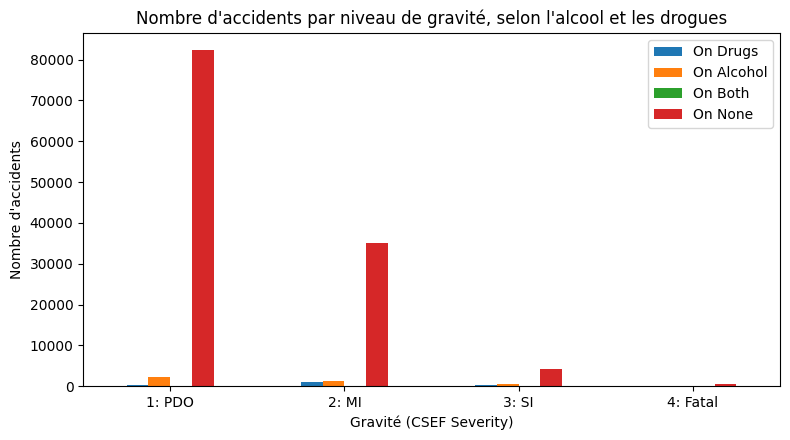

In [33]:
ax = pd_df.plot(kind='bar', x='CSEF Severity', figsize=(8, 4.5))
ax.set_title("Nombre d'accidents par niveau de gravité, selon l'alcool et les drogues")
ax.set_xlabel("Gravité (CSEF Severity)")
ax.set_ylabel("Nombre d'accidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('severe.png')
plt.show()

**Lecture du graphique 1.** Ce graphique est **peu lisible**, et c'est instructif : la série *On None* (122 137 accidents)
écrase les autres (entre 298 et 3 979 accidents), qui sont à peine visibles. Il montre seulement que la grande
majorité des accidents n'implique ni alcool ni drogues, et qu'ils sont surtout matériels (PDO) ou à blessés légers (MI).
**Comparer des nombres absolus entre groupes de tailles très différentes n'a pas de sens** : il faut comparer les
proportions, ce que fait le graphique 2.

**Graphique 2 : répartition en pourcentage de la gravité dans chaque scénario.**

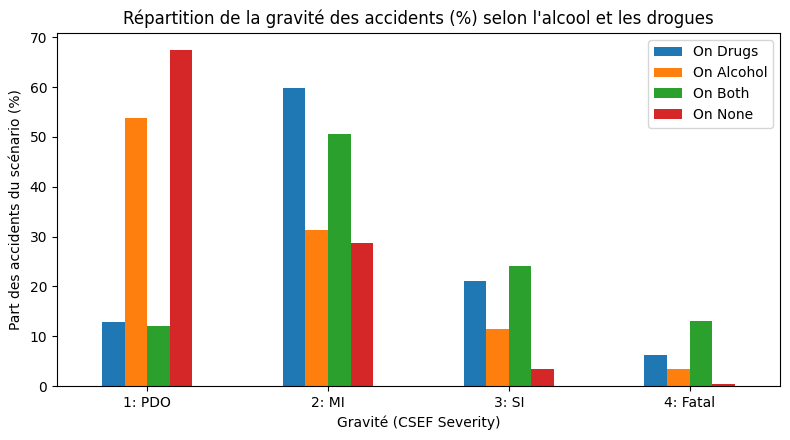

In [34]:
ax = pd_df_per.plot(kind='bar', x='CSEF Severity', figsize=(8, 4.5))
ax.set_title("Répartition de la gravité des accidents (%) selon l'alcool et les drogues")
ax.set_xlabel("Gravité (CSEF Severity)")
ax.set_ylabel("Part des accidents du scénario (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('severe_per.png')
plt.show()

**Lecture du graphique 2.** Dans chaque scénario, les quatre barres de même couleur totalisent 100 %. On peut donc
comparer les profils de gravité, quelle que soit la taille des groupes.
- **Sans alcool ni drogues (rouge)**, les accidents sont majoritairement matériels (67 %), et les accidents graves (SI)
  ou mortels sont rares (3,4 % et 0,4 %).
- **Avec alcool (orange)**, la distribution se décale vers la droite : moins d'accidents matériels (54 %),
  plus de blessés graves (11 %) et de morts (3,4 %).
- **Avec drogues (bleu) ou les deux (vert)**, le profil est inversé : les blessés légers dominent (50 à 60 %), et
  les accidents graves ou mortels représentent entre un quart et plus d'un tiers des cas. La combinaison alcool + drogues
  a la plus forte part d'accidents mortels (13 %).

Conclusion : plus il y a de substances en cause, plus la répartition se déplace vers les niveaux graves.
Cette conclusion doit être nuancée par le biais de dépistage expliqué plus haut.

## 5. Une même requête avec trois API : RDD, DataFrame et Spark SQL

PySpark propose trois façons d'écrire une même requête :
- **RDD** : on manipule des objets Python et on décrit **comment** calculer (bas niveau) ;
- **DataFrame** : on décrit **quoi** calculer avec des opérations sur des colonnes ;
- **Spark SQL** : on écrit une requête SQL sur une **vue temporaire** créée à partir d'un DataFrame
  (`createOrReplaceTempView`).

Les requêtes DataFrame et SQL sont traduites par Catalyst **dans le même plan d'exécution** : elles ont donc les
mêmes performances. Le choix entre les deux est une question de lisibilité.

### 5.1 Requête 1 : accidents à Adelaide
Pour chaque unité impliquée dans un accident à Adelaide : date, heure, nombre de victimes de l'accident, et sexe,
âge et type de permis du conducteur.

**Implémentation RDD (code original).** `parseKey` transforme chaque ligne en `(REPORT_ID, autres colonnes)` ;
`join` associe les paires de même clé : on obtient `(REPORT_ID, (colonnes_units, colonnes_crash))`.
Dans `parseRecord1`, `line[1][0]` désigne les colonnes de *Units*, et `line[1][1]` celles de *Crash*.

In [35]:
# RDD Implementation (code original)
def parseKey(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    return (array_line[0], array_line[1:])

units_rdd1 = units_rdd.map(parseKey)
crash_rdd1 = crash_rdd.map(parseKey)
joined_rdd = units_rdd1.join(crash_rdd1)

def parseRecord1(line):
    if line[1][1][1] == 'ADELAIDE':
        array_line = []
        array_line.append(line[1][1][1])
        array_line.append(line[1][0][7])
        array_line.append(line[1][0][8])
        array_line.append(line[1][0][11])
        array_line.append(line[1][1][12])
        array_line.append(line[1][1][6])
        array_line.append(line[1][1][9] + "-" + line[1][1][10] + "-" + line[1][1][11])
        return (array_line)

pharsed_rdd = joined_rdd.map(parseRecord1)
filtered_pharsed_rdd = pharsed_rdd.filter(lambda x: x is not None)
filtered_pharsed_rdd.take(3)        # l'article fait collect() sur ~12 000 lignes

[['ADELAIDE', '018', 'SA', 'Unknown', '02:10 pm', '0', '2012-April-Friday'],
 ['ADELAIDE', 'XXX', '', '', '02:10 pm', '0', '2012-April-Friday'],
 ['ADELAIDE', '027', 'SA', 'Not Towing', '05:00 pm', '0', '2012-May-Friday']]

**Correction : mauvais indices.** Une fois `REPORT_ID` retiré par `parseKey`, les indices sont décalés de 1 :

| Ce que l'on veut | Indice utilisé | Colonne réellement lue | Bon indice |
|---|---|---|---|
| sexe (units) | 7 | `Age` | 6 |
| âge (units) | 8 | `Lic State` | 7 |
| type de permis (units) | 11 | `Towing` | 10 |
| nombre de victimes (crash) | 6 | `Total Fats` (nombre de **tués**) | 5 |

Dans les lignes ci-dessus, on voit en effet l'âge à la place du sexe, `SA` à la place de l'âge, et `Not Towing`
à la place du type de permis.

**Correction : découpage des lignes.** `split(',')` coupe aussi les virgules **à l'intérieur** des champs entre
guillemets. Par exemple, la commune `"CC OF NORWOOD,PAYNEHAM & ST PETERS"` est coupée en deux, et toutes les colonnes
suivantes sont décalées. C'est le cas de 21 379 lignes de *Crash* (17 %). Le module `csv` de Python, importé par
l'auteur mais jamais utilisé, découpe correctement en respectant les guillemets.

**Version RDD corrigée :**

In [36]:
def parse_csv(line):
    # découpe une ligne CSV en respectant les guillemets : "A,B" reste un seul champ
    return next(csv.reader([line]))

# nombre de lignes de crash mal découpées par split(',') (33 colonnes attendues)
nb_mal_decoupees = crash_rdd.filter(lambda l: len(l.split(',')) != 33).count()
print("Lignes de crash mal découpées par split(','):", nb_mal_decoupees)

units_kv = units_rdd.map(parse_csv).map(lambda a: (a[0], a[1:]))          # (REPORT_ID, colonnes units)
crash_kv = crash_rdd.map(parse_csv).map(lambda a: (a[0], a[1:]))          # (REPORT_ID, colonnes crash)

def adelaide(rec):
    u, c = rec[1]                                    # u : colonnes units, c : colonnes crash
    # (date, heure, victimes, sexe, âge, type de permis, suburb)
    return (c[9] + "-" + c[10] + "-" + c[11], c[12], c[5], u[6], u[7], u[10], c[1])

adelaide_rdd = units_kv.join(crash_kv).filter(lambda rec: rec[1][1][1] == 'ADELAIDE').map(adelaide)
print(adelaide_rdd.take(3))

Lignes de crash mal découpées par split(','): 21379
[('2012-April-Friday', '02:10 pm', '0', 'Female', '018', 'Provisional 1 ', 'ADELAIDE'), ('2012-April-Friday', '02:10 pm', '0', 'Unknown', 'XXX', '', 'ADELAIDE'), ('2012-May-Friday', '05:00 pm', '0', 'Male', '027', 'Full', 'ADELAIDE')]


**Implémentation DataFrame (code original).** La date est construite avec une UDF `find_date`.
L'appel `find_date_udf('Day', 'Month', 'Year')` passe les colonnes dans l'ordre `(d, m, y)`, et la fonction
renvoie `y-m-d`, donc `Année-Mois-JourDeLaSemaine` : le format demandé.

In [37]:
# DataFrame implementation (code original)
joined_df = crash_df.join(units_df, crash_df.REPORT_ID == units_df.REPORT_ID, how='inner')
def find_date(d, m, y):
    return y + "-" + m + "-" + d

find_date_udf = udf(find_date)
joined_date_df = joined_df.withColumn('Date', find_date_udf('Day', 'Month', 'Year'))
joined_date_df = joined_date_df.filter(col("Suburb") == 'ADELAIDE')
adelaide_df = joined_date_df.select('Date', 'Time', 'Total Cas', 'Sex', 'Age', 'Licence Type', 'Suburb')
adelaide_df.show(5, truncate=False)

+-------------------+--------+---------+------+---+-------------+--------+
|Date               |Time    |Total Cas|Sex   |Age|Licence Type |Suburb  |
+-------------------+--------+---------+------+---+-------------+--------+
|2012-January-Monday|08:45 am|0        |Male  |084|Full         |ADELAIDE|
|2012-January-Monday|08:45 am|0        |Male  |040|Full         |ADELAIDE|
|2012-January-Friday|05:45 pm|0        |Male  |047|Full         |ADELAIDE|
|2012-January-Friday|05:45 pm|0        |Male  |XXX|NULL         |ADELAIDE|
|2012-January-Friday|07:30 pm|1        |Female|018|Provisional 2|ADELAIDE|
+-------------------+--------+---------+------+---+-------------+--------+
only showing top 5 rows



*Amélioration possible :* la fonction intégrée `F.concat_ws('-', 'Year', 'Month', 'Day')` produit la même date
sans UDF, donc sans passer par Python.

**Implémentation Spark SQL (code original).** Les DataFrames sont enregistrés comme vues temporaires
(`units_table`, `crash_table`), visibles uniquement dans cette session. `||` est l'opérateur SQL de concaténation.
Les noms de colonnes contenant des espaces s'écrivent entre accents graves : `` `Total Cas` ``.

In [38]:
# SparkSQL implementation (code original)
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")
joined_table = spark.sql('''
  SELECT (Year || '-' || Month || '-' || Day) as Date, Time, `Total Cas`, Sex, Age, `Licence Type`, Suburb
  FROM units_table u JOIN crash_table c
  ON u.REPORT_ID = c.REPORT_ID
  where c.Suburb == 'ADELAIDE'
''')
joined_table.show(5, truncate=False)

+-------------------+--------+---------+------+---+-------------+--------+
|Date               |Time    |Total Cas|Sex   |Age|Licence Type |Suburb  |
+-------------------+--------+---------+------+---+-------------+--------+
|2012-January-Monday|08:45 am|0        |Male  |084|Full         |ADELAIDE|
|2012-January-Monday|08:45 am|0        |Male  |040|Full         |ADELAIDE|
|2012-January-Friday|05:45 pm|0        |Male  |047|Full         |ADELAIDE|
|2012-January-Friday|05:45 pm|0        |Male  |XXX|NULL         |ADELAIDE|
|2012-January-Friday|07:30 pm|1        |Female|018|Provisional 2|ADELAIDE|
+-------------------+--------+---------+------+---+-------------+--------+
only showing top 5 rows



**Vérification : les trois implémentations donnent-elles le même résultat ?** On compare les ensembles de lignes
(converties en texte, les valeurs vides étant représentées par une chaîne vide).

In [39]:
def en_texte(rows):
    return sorted(tuple('' if v is None else str(v) for v in r) for r in rows)

r_rdd = en_texte(adelaide_rdd.collect())
r_df = en_texte(adelaide_df.collect())
r_sql = en_texte(joined_table.collect())
print("Nombre de lignes : RDD", len(r_rdd), "| DataFrame", len(r_df), "| SQL", len(r_sql))
assert r_rdd == r_df == r_sql
print("Les trois implémentations donnent exactement le même résultat.")

Nombre de lignes : RDD 11965 | DataFrame 11965 | SQL 11965
Les trois implémentations donnent exactement le même résultat.


### 5.2 Requête 2 : victimes par suburb pour les conducteurs sans permis

**Code original (trois implémentations).** Nous les exécutons, mais nous n'affichons que leur nombre de lignes et
leur total, au lieu de `collect()` sur des centaines de suburbs.

In [40]:
# RDD implementation (code original)
def parseRecord2(line):
    return (line[1][1][1], int(line[1][1][5]))

filtered_rdd = joined_rdd.filter(lambda x: (x[1][0][9] != "XX") & (x[1][0][8] != "UNKNOWN") & (x[1][0][10] != "Unknown")
                                 & (x[1][0][9] is not None) & (x[1][0][10] is not None) & (x[1][0][11] is not None))
pharased_filtered_rdd = filtered_rdd.map(parseRecord2)
result = pharased_filtered_rdd.groupByKey().mapValues(lambda x: sum(x))

# DataFrame implementation (code original)
without_lic_df = joined_df.dropna(subset=('Licence Type', 'Licence Class', 'Lic State'), how='all')
by_suburb_no_lic_no_df2 = without_lic_df.filter((col('Licence Type') != 'Unknown') & (col('Licence Class') != 'XX')
                                                & (col('Lic State') != 'UNKNOWN'))\
                                        .groupby('Suburb').agg(F.count('No Of Cas').alias('Total casualty'))

# SparkSQL implementation (code original)
sql_original = spark.sql('''
  SELECT Suburb, COUNT(`Total Cas`)
  FROM units_table u JOIN crash_table c
  ON u.REPORT_ID = c.REPORT_ID
  WHERE `Lic State` IS NOT NULL and `Licence Class` IS NOT NULL and `Licence Type` IS NOT NULL and
  `Licence Type` != 'Unknown' and
  `Licence Class` != 'XX' and
  `Lic State` != 'UNKNOWN'
GROUP BY Suburb
''')

print("RDD       : total =", sum(v for _, v in result.collect()))
print("DataFrame : total =", by_suburb_no_lic_no_df2.agg(F.sum('Total casualty')).first()[0])
print("SQL       : total =", sql_original.agg(F.sum(sql_original.columns[1])).first()[0])

RDD       : total = 127681
DataFrame : total = 180182
SQL       : total = 180182


**Correction : trois résultats différents pour une même question.** Les trois versions originales ne calculent
pas la même chose, et aucune ne répond à la question posée :
- aucune ne garde les conducteurs **sans permis** (`Licence Type = 'Unlicenced'`). Elles gardent au contraire les
  unités dont le permis n'est **pas inconnu**, donc surtout des titulaires du permis ;
- elles ne mesurent pas la même chose : le RDD **additionne** `Total Cas` (des victimes), alors que le DataFrame
  (`F.count('No Of Cas')`) et le SQL (`COUNT(Total Cas)`) **comptent des lignes**, c'est-à-dire des unités.
  Ces deux dernières tombent sur le même total (180 182), mais ce n'est pas un nombre de victimes ;
- elles ne filtrent pas les mêmes lignes : dans le RDD, les tests `is not None` sont inutiles, car `split` produit
  des chaînes vides (`''`) et jamais `None`. Les unités sans permis renseigné (piétons, obstacles) sont donc gardées,
  alors que le DataFrame et le SQL les excluent ;
- le RDD souffre en plus du `split(',')` : pour les 17 % d'accidents dont le nom de commune contient une virgule,
  l'indice 5 ne désigne plus `Total Cas` mais `Total Units` ;
- toutes les trois comptent un accident plusieurs fois s'il implique plusieurs unités retenues (section 4.4).

**Versions corrigées et cohérentes.** Définition commune : pour chaque suburb, la **somme des victimes (`Total Cas`)
des accidents distincts impliquant au moins un conducteur sans permis**. On vérifie ensuite que les trois versions
donnent exactement le même résultat.

In [41]:
from operator import add

# --- RDD ---
ids_rdd = (units_rdd.map(parse_csv)
           .filter(lambda a: a[11] == 'Unlicenced')          # colonne 11 = Licence Type
           .map(lambda a: (a[0], None))                      # (REPORT_ID, None)
           .distinct())                                      # chaque accident une seule fois
q2_rdd = (crash_rdd.map(parse_csv)
          .map(lambda a: (a[0], (a[2], int(a[6]))))          # (REPORT_ID, (Suburb, Total Cas))
          .join(ids_rdd)                                     # ne garde que les accidents concernés
          .map(lambda kv: kv[1][0])                          # (Suburb, Total Cas)
          .reduceByKey(add))                                 # somme par suburb

# --- DataFrame (voir section 4.4) ---
q2_df = victimes_sans_permis_df

# --- Spark SQL ---
q2_sql = spark.sql('''
  SELECT Suburb, SUM(`Total Cas`) AS `Total casualty`
  FROM crash_table
  WHERE REPORT_ID IN (SELECT REPORT_ID FROM units_table WHERE `Licence Type` = 'Unlicenced')
  GROUP BY Suburb
''')

d_rdd = dict(q2_rdd.collect())
d_df = {r['Suburb']: r['Total casualty'] for r in q2_df.collect()}
d_sql = {r['Suburb']: r['Total casualty'] for r in q2_sql.collect()}
assert d_rdd == d_df == d_sql
print(f"Les trois implémentations donnent le même résultat : {len(d_df)} suburbs, {sum(d_df.values())} victimes.")
q2_sql.sort(col('Total casualty').desc()).show(10)

Les trois implémentations donnent le même résultat : 752 suburbs, 2053 victimes.
+--------------+--------------+
|        Suburb|Total casualty|
+--------------+--------------+
|      ADELAIDE|            42|
|     SALISBURY|            30|
|      PROSPECT|            27|
|    INGLE FARM|            22|
| MORPHETT VALE|            20|
| MURRAY BRIDGE|            19|
|SALISBURY EAST|            19|
|     DRY CREEK|            19|
|NORTH ADELAIDE|            17|
|  MAWSON LAKES|            17|
+--------------+--------------+
only showing top 10 rows



En SQL, `WHERE REPORT_ID IN (sous-requête)` joue le rôle de la semi-jointure de la version DataFrame :
chaque accident n'est gardé qu'une fois, même si plusieurs conducteurs sans permis y sont impliqués.

On peut vérifier que Catalyst traduit la requête SQL en une semi-jointure, comme la version DataFrame,
avec `explain()`, qui affiche le plan physique d'exécution :

In [42]:
q2_sql.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=true
+- == Final Plan ==
   *(3) HashAggregate(keys=[Suburb#142], functions=[sum(Total Cas#305)])
   +- AQEShuffleRead coalesced
      +- ShuffleQueryStage 1
         +- Exchange hashpartitioning(Suburb#142, 200), ENSURE_REQUIREMENTS, [plan_id=8371]
            +- *(2) HashAggregate(keys=[Suburb#142], functions=[partial_sum(Total Cas#305)])
               +- *(2) Project [Suburb#142, cast(Total Cas#146 as int) AS Total Cas#305]
                  +- *(2) BroadcastHashJoin [REPORT_ID#140], [REPORT_ID#87], LeftSemi, BuildRight, false
                     :- FileScan csv [REPORT_ID#140,Suburb#142,Total Cas#146] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(8 paths)[file:/C:/Users/Brahimi/Desktop/2026_2027/Big_Data/Big_Data/crash_data/..., PartitionFilters: [], PushedFilters: [], ReadSchema: struct<REPORT_ID:string,Suburb:string,Total Cas:string>
                     +- BroadcastQueryStage 0
                      

**Lecture du plan.** Il se lit **de bas en haut** : lecture des fichiers CSV (`FileScan csv`) en ne gardant que les
colonnes utiles (`ReadSchema` : seulement `REPORT_ID`, `Suburb` et `Total Cas` pour *Crash*) ; filtre
`Licence Type = Unlicenced` sur *Units* ; jointure **`LeftSemi`** réalisée en **`BroadcastHashJoin`** : la petite
liste des accidents concernés est copiée vers chaque tâche, ce qui évite de redistribuer la grande table *Crash* ;
puis agrégation en deux temps (`HashAggregate` partiel dans chaque partition, échange `Exchange hashpartitioning(Suburb)`,
c'est-à-dire le shuffle, puis `HashAggregate` final). On retrouve exactement les phases map → combiner → shuffle → reduce
du modèle MapReduce vu dans le TP précédent.

### 5.3 Comparaison des temps d'exécution
On mesure le temps de la requête 2 corrigée avec chaque API (médiane de 3 exécutions).
**Attention à un piège de mesure :** si l'on relance `collect()` sur le **même** objet, Spark réutilise les fichiers
intermédiaires du shuffle déjà calculés, et les exécutions suivantes paraissent presque instantanées. Pour une
comparaison honnête, chaque mesure **reconstruit la requête** à partir des fichiers CSV.

In [43]:
import time, statistics

def chrono(action, n=3):
    temps = []
    for _ in range(n):
        t0 = time.perf_counter()
        action()
        temps.append(time.perf_counter() - t0)
    return statistics.median(temps)

def q2_rdd_neuf():
    u = sc.textFile(UNITS_TXT).filter(lambda r: r != units_header).map(parse_csv)
    c = sc.textFile(CRASH_TXT).filter(lambda r: r != crash_header).map(parse_csv)
    ids = u.filter(lambda a: a[11] == 'Unlicenced').map(lambda a: (a[0], None)).distinct()
    return (c.map(lambda a: (a[0], (a[2], int(a[6])))).join(ids)
             .map(lambda kv: kv[1][0]).reduceByKey(add).collect())

def q2_df_neuf():
    u = spark.read.option('header', True).option('escape', '"').csv(UNITS_FILES)
    c = spark.read.option('header', True).option('escape', '"').csv(CRASH_FILES)
    ids = u.filter(col('Licence Type') == 'Unlicenced').select('REPORT_ID').distinct()
    return (c.join(ids, 'REPORT_ID', 'left_semi').groupBy('Suburb')
             .agg(F.sum(col('Total Cas').cast('int')).alias('Total casualty')).collect())

def q2_sql_neuf():
    spark.read.option('header', True).option('escape', '"').csv(UNITS_FILES).createOrReplaceTempView('u_t')
    spark.read.option('header', True).option('escape', '"').csv(CRASH_FILES).createOrReplaceTempView('c_t')
    return spark.sql('''SELECT Suburb, SUM(CAST(`Total Cas` AS INT)) AS `Total casualty` FROM c_t
                        WHERE REPORT_ID IN (SELECT REPORT_ID FROM u_t WHERE `Licence Type` = 'Unlicenced')
                        GROUP BY Suburb''').collect()

temps = pd.DataFrame({
    'API': ['RDD', 'DataFrame', 'Spark SQL'],
    'Temps (s)': [round(chrono(q2_rdd_neuf), 2),
                  round(chrono(q2_df_neuf), 2),
                  round(chrono(q2_sql_neuf), 2)]})
temps

,API,Temps (s)
0,RDD,44.23
1,DataFrame,1.67
2,Spark SQL,1.01


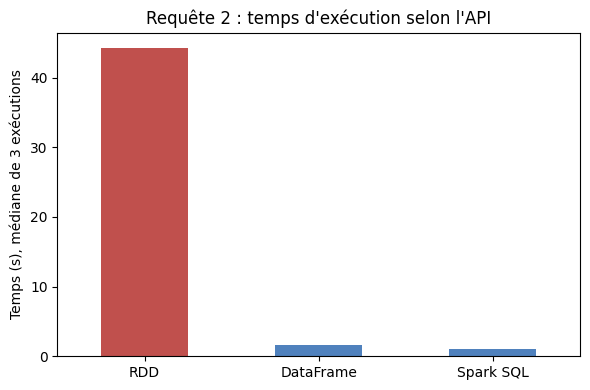

In [44]:
ax = temps.plot(kind='bar', x='API', y='Temps (s)', legend=False, figsize=(6, 4), color=['#c0504d', '#4f81bd', '#4f81bd'])
ax.set_title("Requête 2 : temps d'exécution selon l'API")
ax.set_xlabel("")
ax.set_ylabel("Temps (s), médiane de 3 exécutions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('temps_api.png')
plt.show()

**Lecture du graphique 3.** Les versions **DataFrame et Spark SQL ont des temps quasi identiques** : c'est attendu,
puisque Catalyst les traduit dans le même plan d'exécution (voir `explain()` ci-dessus).
La version **RDD est nettement plus lente** (ici environ 3 fois) : chaque ligne est envoyée à un processus Python pour être découpée par
`csv.reader`, puis renvoyée à la JVM (sérialisation dans les deux sens), et Spark ne peut ni ignorer les colonnes
inutiles ni optimiser l'ordre des opérations. C'est la même conclusion que pour le comptage de mots du TP précédent
(Spark RDD contre Spark DataFrame). Les valeurs exactes dépendent de la machine.

## 6. Conclusion

**Sur les données.**
- Les accidents d'Australie-Méridionale (2012-2019) sont majoritairement matériels (66 %) ; 0,57 % sont mortels.
- Les collisions contre un obstacle fixe et les collisions frontales sont les plus meurtrières.
- La gravité est fortement **associée** à la présence d'alcool et surtout de drogues : la part d'accidents mortels passe
  de 0,4 % sans substance à 3,4 % avec alcool, 6,3 % avec drogues et 13 % avec les deux. Ces chiffres doivent être
  interprétés avec prudence, car le dépistage est plus systématique pour les accidents graves.

**Sur PySpark.**

| | RDD | DataFrame | Spark SQL |
|---|---|---|---|
| Niveau | bas : objets Python, on décrit *comment* | haut : colonnes, on décrit *quoi* | haut : requête SQL |
| Schéma connu de Spark | non (indices de colonnes à la main) | oui | oui |
| Optimisation (Catalyst) | non | oui | oui (même plan que DataFrame) |
| Exécution | fonctions Python (lent en PySpark) | JVM, code compilé | JVM, code compilé |
| Risque d'erreur | élevé (indices, découpage CSV) | faible | faible |

La reprise de ce code illustre ce dernier point : **toutes les erreurs trouvées dans l'article concernent les RDD**
(indices de colonnes erronés, découpage CSV naïf), ou bien la logique de la requête (double comptage après jointure),
qui est indépendante de l'API. Avec les DataFrames et SQL, Spark lit correctement les CSV et désigne les colonnes par
leur nom. Ils sont aussi plus rapides.

**Bonnes pratiques retenues.**
1. Préférer les DataFrames ou SQL aux RDD en PySpark, et les fonctions intégrées aux UDF Python.
2. Préférer `reduceByKey` à `groupByKey`, et `take` / `takeOrdered` à `collect()` sur de gros volumes.
3. Agréger avec Spark avant `toPandas()` et les graphiques.
4. Après une jointure 1 → n, vérifier qu'on ne compte pas plusieurs fois la même entité.
5. **Vérifier** les résultats en comparant plusieurs implémentations : c'est ce qui a permis de trouver les erreurs.

In [45]:
spark.stop()     # libère la JVM et les ressources de Spark